In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
symbol = 'EURUSD=X'

In [3]:
data_test = yf.download(symbol, start='2020-01-01', end='2021-01-01')['Close'][symbol]
df_test = pd.DataFrame(data_test)
df_test.rename(columns={f'{symbol}': 'Close'}, inplace=True)
df_test.reset_index(inplace=True)
df_test = df_test[['Close']]
# df_test
long_period = 20
short_period = 5
df_test['MA_long'] = df_test['Close'].rolling(long_period).mean()
df_test['MA_short'] = df_test['Close'].rolling(short_period).mean()
df_test['pct_change']= abs(df_test['Close'].diff())/df_test['Close'].shift(1)
df_test.dropna(inplace=True)
df_test

n = 3

import math

df_test['MA_long_slope'] = np.degrees(np.arctan(df_test['MA_long'].diff(n))/n)
df_test['MA_short_slope'] = np.degrees(np.arctan(df_test['MA_short'].diff(n))/n)
df_test.dropna(inplace=True)
median_long_slope = abs(df_test['MA_long_slope']).median()
median_short_slope = abs(df_test['MA_short_slope']).median()
median_pct_change = abs(df_test['pct_change']).median()
# median_angle = abs(df_test['angle']).median()
# median_diff_MA = abs(df_test['diff_MA']).median()
print(f'median_long_slope: {median_long_slope}')
print(f'median_short_slope: {median_short_slope}')
print(f'median_pct_change: {median_pct_change}')
# print(f'median_ange: {median_angle}')
# print(f'median_diff_MA: {median_diff_MA}')

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed

median_long_slope: 0.041798698825139424
median_short_slope: 0.08217236044709708
median_pct_change: 0.0031007194236418556


[*********************100%***********************]  1 of 1 completed


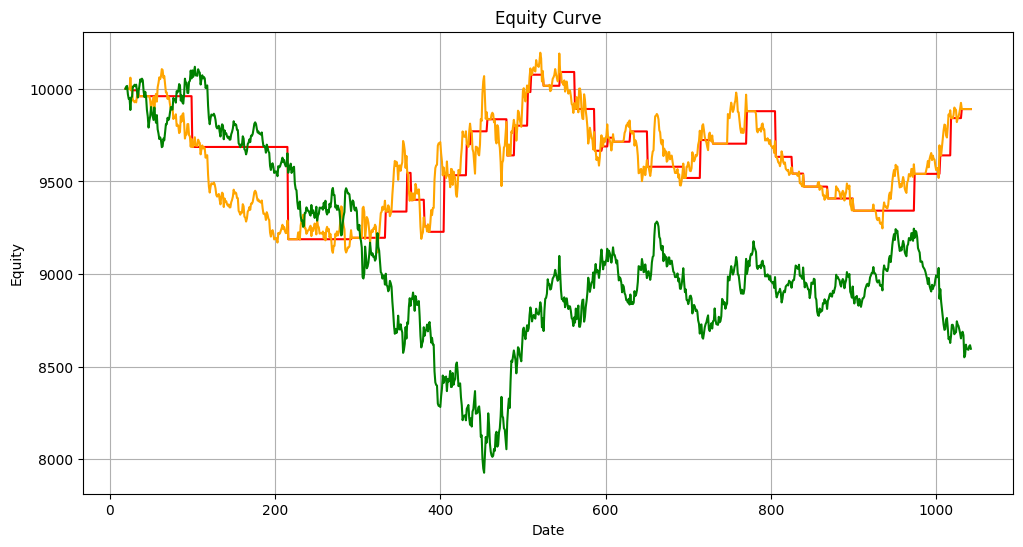

sharpe_ratio: -0.25057570473478263
unrl_sharpe_ratio: -1.4327129435411627


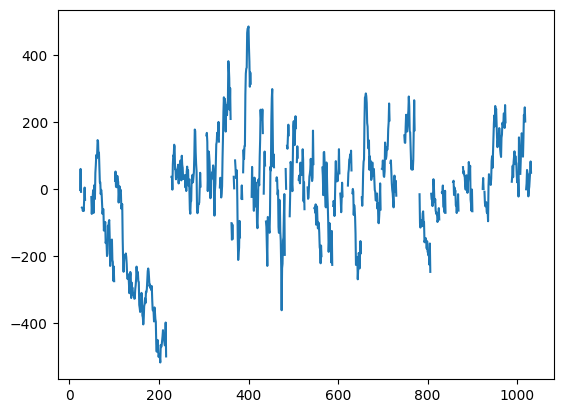

In [4]:
data = yf.download(symbol, start='2021-01-01', end='2025-01-01')['Close'][symbol]
df = pd.DataFrame(data)
df.rename(columns={f'{symbol}': 'Close'}, inplace=True)
df.reset_index(inplace=True)
df = df[['Date','Close']]
# df_test
long_period = 20
short_period = 5
df['MA_long'] = df['Close'].rolling(long_period).mean()
df['MA_short'] = df['Close'].rolling(short_period).mean()
df['pct_change'] = df['Close'].pct_change()
df.dropna(inplace=True)
df

n = 3


df['MA_long_slope'] = np.degrees(np.arctan(df['MA_long'].diff(n))/n)
df['MA_short_slope'] = np.degrees(np.arctan(df['MA_short'].diff(n))/n)
# max_short_slope_entry = 60
# Check if MAs are parallel
df['angle'] = df['MA_short_slope'] - df['MA_long_slope']
df['diff_MA'] = df['MA_short'] - df['MA_long']

df['MA_short_slope_change'] = df['MA_short_slope'].diff()
df['MA_long_slope_change'] = df['MA_long_slope'].diff()


slope_threshold_entry = 1.003* median_long_slope
slope_threshold_exit = -0.3* median_short_slope
angle_diff_threshold = 5

signal = None
position = 0
initial_balance = 10000
balance = initial_balance
equity = initial_balance
equity_curve = []
entry_buy = 0
exit_buy = 0
entry_sell = 0
exit_sell  = 0
pnl_series = []
unrl_pnl_series = []
temp_unr = []
for i, row in df.iterrows():
  tp_sl_threshold = 0.1 *df.at[i,'Close']
  if not position:
    equity = equity
    equity_curve.append(equity)
    balance = balance

    # abs(df.at[i,'angle']) < angle_diff_threshold and
    if  df.at[i,'MA_long_slope'] > slope_threshold_entry and abs(df.at[i,'angle']) <10:
      # if df.at[i,'Close'] > df.at[i-1,'Close'] and df.at[i-2,'Close'] > df.at[i-1,'Close']:
        position = balance/df.at[i,'Close']
        # balance -= balance
        entry_buy = df.at[i,'Close']
    elif df.at[i,'MA_long_slope'] < -slope_threshold_entry and abs(df.at[i,'angle']) <10:
      # if df.at[i,'Close'] < df.at[i-1,'Close'] and df.at[i-2,'Close'] < df.at[i-1,'Close']:
        position = -balance/df.at[i,'Close']
        # balance -= balance
        entry_sell = df.at[i,'Close']

  elif position > 0:
    unr_pnl = (df.at[i,'Close'] - entry_buy)*position
    df.at[i,'unrl_pnl'] = unr_pnl
    equity = balance + unr_pnl

    df.at[i,'temp_urn'] = unr_pnl
    if temp_unr:
      # if (df.at[i,'MA_short_slope'] <slope_threshold_exit) or
      if(df.at[i,'Close']*(1+median_pct_change) < df.at[i-1,'Close'] and df.at[i-2,'Close']*(1+median_pct_change) < df.at[i-1,'Close']):
      # if (unr_pnl <= 0.7*max(temp_unr)) or (unr_pnl >=2* max(temp_unr)) or (unr_pnl >= 1.7 * temp_unr[-1]):
        df.at[i,'pnl'] = (df.at[i,'Close'] - entry_buy)*position
        entry_buy = 0
        position = 0
        balance += unr_pnl
        temp_unr.clear()
      else: temp_unr.append(unr_pnl)
    else: temp_unr.append(unr_pnl)
  elif position < 0:
    unr_pnl = (df.at[i,'Close'] - entry_sell)*position
    df.at[i,'unrl_pnl'] = unr_pnl
    equity = balance +  unr_pnl
    df.at[i,'temp_urn'] = unr_pnl
    if temp_unr:
      # if df.at[i,'MA_short_slope'] >-slope_threshold_exit or
      if (df.at[i,'Close']*(1-median_pct_change) > df.at[i-1,'Close'] and df.at[i-2,'Close']*(1-median_pct_change) > df.at[i-1,'Close']):
      # if (unr_pnl <= 0.7*max(temp_unr)) or (unr_pnl >=2* max(temp_unr)) or (unr_pnl >= 1.7 * temp_unr[-1]):# or unr_pnl >=tp_sl_threshold or unr_pnl < -tp_sl_threshold:
        df.at[i,'pnl'] = unr_pnl
        entry_sell = 0
        position = 0
        balance += unr_pnl
        temp_unr.clear()
      else: temp_unr.append(unr_pnl)
    else:temp_unr.append(unr_pnl)


  df.at[i,'balance'] = balance
  df.at[i,'equity'] = equity
  df.at[i,'position'] = position

initial_position = 10000/df['Close'].iloc[0]
df['buy_n_hold'] = initial_position * df['Close']





import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['balance'],color = 'red')
plt.plot(df.index, df['equity'],color = 'orange')
plt.plot(df.index,df['buy_n_hold'], color = 'green')
plt.title('Equity Curve')
plt.xlabel('Date')
plt.ylabel('Equity')
plt.grid(True)
plt.show()
sharpe_ratio = (df['pnl'].mean()/df['pnl'].std())*np.sqrt(252)
unrl_sharpe_ratio = (df['unrl_pnl'].mean()/df['unrl_pnl'].std())*np.sqrt(252)
print(f'sharpe_ratio: {sharpe_ratio}')
print(f'unrl_sharpe_ratio: {unrl_sharpe_ratio}')
plt.plot(df['temp_urn'])
# df

In [5]:
pnl_check = df[['Date','Close','position','angle','equity','pnl','unrl_pnl']]
pnl_check

,Date,Close,position,angle,equity,pnl,unrl_pnl
19,2021-01-28,1.210507,0.000000,NaN,10000.000000,NaN,NaN
20,2021-01-29,1.212004,0.000000,NaN,10000.000000,NaN,NaN
21,2021-02-01,1.212386,0.000000,NaN,10000.000000,NaN,NaN
22,2021-02-02,1.206869,0.000000,-0.029373,10000.000000,NaN,NaN
23,2021-02-03,1.203905,-8306.300042,-0.039851,10000.000000,NaN,NaN
...,...,...,...,...,...,...,...
1038,2024-12-25,1.040258,0.000000,-0.090716,9890.638327,NaN,NaN
1039,2024-12-26,1.039955,0.000000,-0.031397,9890.638327,NaN,NaN
1040,2024-12-27,1.042318,0.000000,0.043123,9890.638327,NaN,NaN
1041,2024-12-30,1.042938,0.000000,0.079617,9890.638327,NaN,NaN


In [6]:
print(df['pnl'].count())


44
